# How Cosine Similarity Is Calculated for `"puppy"` and `"dog"`

To find the cosine similarity between `"puppy"` and `"dog"`, the computer takes all 768 numbers of `"puppy"` and all 768 numbers of `"dog"` and runs a 4-step math recipe. It multiplies matching positions, adds them up, measures the length of each arrow, and divides them to get one final score.

Here is the step-by-step cookbook using both a tiny 3-number toy example (so you and your kid can solve it with a pocket calculator) and a Python cell that shows every step using all 768 numbers from your local `nomic-embed-text` model.

---

## The 4-Step Cosine Similarity Cookbook (3-Number Example)

Imagine `"puppy"` and `"dog"` only had **3 dials** instead of 768:
* **`puppy` ($\vec{A}$):** `[0.8, 0.5, 0.2]`
* **`dog` ($\vec{B}$):** `[0.7, 0.6, 0.1]`

### Step 1: Multiply Matching Dials (Dot Product)
Multiply Dial 1 by Dial 1, Dial 2 by Dial 2, and Dial 3 by Dial 3, then add the results together:
* **Dial 1:** $0.8 \times 0.7 = 0.56$
* **Dial 2:** $0.5 \times 0.6 = 0.30$
* **Dial 3:** $0.2 \times 0.1 = 0.02$
* **Total Dot Product ($\vec{A} \cdot \vec{B}$):** $0.56 + 0.30 + 0.02 = \mathbf{0.88}$

### Step 2: Find the Length of the `"puppy"` Arrow ($\|\vec{A}\|$)
Square each number in `"puppy"`, add them up, and take the square root:
* **Squares:** $0.8^2 + 0.5^2 + 0.2^2 = 0.64 + 0.25 + 0.04 = 0.93$
* **Square Root:** $\sqrt{0.93} \approx \mathbf{0.964}$

### Step 3: Find the Length of the `"dog"` Arrow ($\|\vec{B}\|$)
Do the exact same thing for `"dog"`:
* **Squares:** $0.7^2 + 0.6^2 + 0.1^2 = 0.49 + 0.36 + 0.01 = 0.86$
* **Square Root:** $\sqrt{0.86} \approx \mathbf{0.927}$

### Step 4: Divide Step 1 by (Step 2 × Step 3)
Divide the total overlap by the combined arrow lengths:

$$\text{Cosine Similarity} = \frac{0.88}{0.964 \times 0.927} = \frac{0.88}{0.894} \approx \mathbf{0.984}$$

> **Shortcut note:** Many embedding models like `nomic-embed-text` automatically pre-stretch every arrow so its length in Steps 2 and 3 is already **`1.000`**! When both lengths equal `1`, Step 1 alone gives the exact answer.


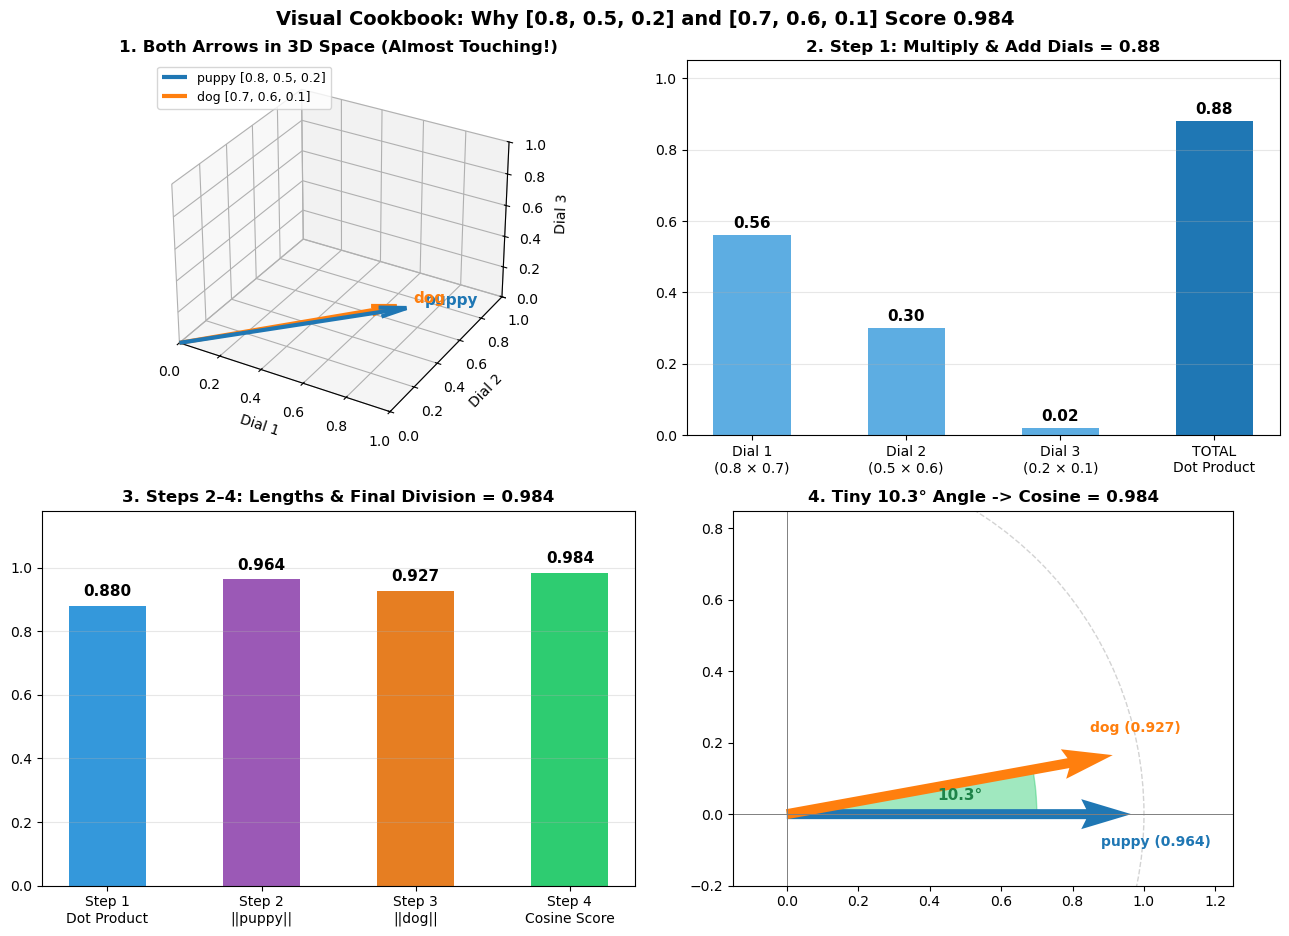

In [6]:
# %% Cell: Graphical Dashboard for the 3-Number Toy Example ("puppy" vs "dog")
import math
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Wedge

# Your exact 3-number vectors from the cookbook
puppy = np.array([0.8, 0.5, 0.2])
dog = np.array([0.7, 0.6, 0.1])

# --- Run the 4 Cookbook Steps ---
dial_products = puppy * dog                         # [0.56, 0.30, 0.02]
dot_product = float(np.sum(dial_products))          # 0.880
len_puppy = float(np.sqrt(np.sum(puppy ** 2)))      # 0.964
len_dog = float(np.sqrt(np.sum(dog ** 2)))          # 0.927
cos_sim = dot_product / (len_puppy * len_dog)       # 0.984
angle_deg = math.degrees(math.acos(cos_sim))        # 10.2°

# --- Build 2x2 Graphical Dashboard ---
fig = plt.figure(figsize=(13, 9.5))

# 1. TOP LEFT: 3D Arrows in 3-Dial Space
ax1 = fig.add_subplot(2, 2, 1, projection="3d")
ax1.quiver(0, 0, 0, *puppy, color="#1f77b4", linewidth=3, arrow_length_ratio=0.12, label="puppy [0.8, 0.5, 0.2]")
ax1.quiver(0, 0, 0, *dog, color="#ff7f0e", linewidth=3, arrow_length_ratio=0.12, label="dog [0.7, 0.6, 0.1]")
ax1.text(*puppy * 1.08, "puppy", color="#1f77b4", fontweight="bold", fontsize=11)
ax1.text(*dog * 1.08, "dog", color="#ff7f0e", fontweight="bold", fontsize=11)
ax1.set_xlim(0, 1)
ax1.set_ylim(0, 1)
ax1.set_zlim(0, 1)
ax1.set_xlabel("Dial 1")
ax1.set_ylabel("Dial 2")
ax1.set_zlabel("Dial 3")
ax1.set_title("1. Both Arrows in 3D Space (Almost Touching!)", fontweight="bold")
ax1.legend(loc="upper left", fontsize=9)

# 2. TOP RIGHT: Step 1 Dial-by-Dial Multiplication
ax2 = fig.add_subplot(2, 2, 2)
dials = ["Dial 1\n(0.8 × 0.7)", "Dial 2\n(0.5 × 0.6)", "Dial 3\n(0.2 × 0.1)", "TOTAL\nDot Product"]
vals = [0.56, 0.30, 0.02, dot_product]
cols = ["#5dade2", "#5dade2", "#5dade2", "#1f77b4"]
bars2 = ax2.bar(dials, vals, color=cols, width=0.5)
ax2.set_ylim(0, 1.05)
for b, v in zip(bars2, vals):
    ax2.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.2f}", ha="center", fontweight="bold", fontsize=11)
ax2.set_title("2. Step 1: Multiply & Add Dials = 0.88", fontweight="bold")
ax2.grid(axis="y", alpha=0.3)

# 3. BOTTOM LEFT: Steps 2, 3 & 4 Summary Bars
ax3 = fig.add_subplot(2, 2, 3)
step_names = ["Step 1\nDot Product", "Step 2\n||puppy||", "Step 3\n||dog||", "Step 4\nCosine Score"]
step_vals = [dot_product, len_puppy, len_dog, cos_sim]
step_cols = ["#3498db", "#9b59b6", "#e67e22", "#2ecc71"]
bars3 = ax3.bar(step_names, step_vals, color=step_cols, width=0.5)
ax3.set_ylim(0, 1.18)
for b, v in zip(bars3, step_vals):
    ax3.text(b.get_x() + b.get_width() / 2, v + 0.03, f"{v:.3f}", ha="center", fontweight="bold", fontsize=11)
ax3.set_title("3. Steps 2–4: Lengths & Final Division = 0.984", fontweight="bold")
ax3.grid(axis="y", alpha=0.3)

# 4. BOTTOM RIGHT: Exact 10.2° Angle Protractor Wedge
ax4 = fig.add_subplot(2, 2, 4)
rad = math.radians(angle_deg)
ax4.add_patch(plt.Circle((0, 0), 1.0, color="lightgray", fill=False, linestyle="--"))
ax4.add_patch(Wedge((0, 0), 0.7, 0, angle_deg, color="#2ecc71", alpha=0.45))

# Draw 'puppy' (length 0.964) at 0° and 'dog' (length 0.927) at 10.2°
ax4.quiver(0, 0, len_puppy, 0, angles="xy", scale_units="xy", scale=1, color="#1f77b4", width=0.02)
ax4.quiver(0, 0, len_dog * math.cos(rad), len_dog * math.sin(rad), angles="xy", scale_units="xy", scale=1, color="#ff7f0e", width=0.02)

ax4.text(0.88, -0.09, "puppy (0.964)", color="#1f77b4", fontweight="bold", fontsize=10)
ax4.text(0.85, 0.23, "dog (0.927)", color="#ff7f0e", fontweight="bold", fontsize=10)
ax4.text(0.42, 0.04, f"{angle_deg:.1f}°", fontweight="bold", fontsize=11, color="#1e8449")

ax4.set_xlim(-0.15, 1.25)
ax4.set_ylim(-0.2, 0.85)
ax4.set_aspect("equal")
ax4.axhline(0, color="gray", linewidth=0.7)
ax4.axvline(0, color="gray", linewidth=0.7)
ax4.set_title(f"4. Tiny {angle_deg:.1f}° Angle -> Cosine = {cos_sim:.3f}", fontweight="bold")

plt.suptitle("Visual Cookbook: Why [0.8, 0.5, 0.2] and [0.7, 0.6, 0.1] Score 0.984", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


# Below code refers 4-Step Cookbook + Live Angle Graphs (puppy vs. dog & banana)

================ PUPPY vs DOG ================
  Step 1 (Dot Product)    = 0.789710
  Step 2 (||puppy||)     = 1.000000
  Step 3 (||dog||)     = 1.000000
  Step 4 (Cosine Sim)     = 0.789710
  Resulting Angle (theta) = 37.84°

================ PUPPY vs BANANA ================
  Step 1 (Dot Product)    = 0.361722
  Step 2 (||puppy||)     = 1.000000
  Step 3 (||banana||)     = 1.000000
  Step 4 (Cosine Sim)     = 0.361722
  Resulting Angle (theta) = 68.79°



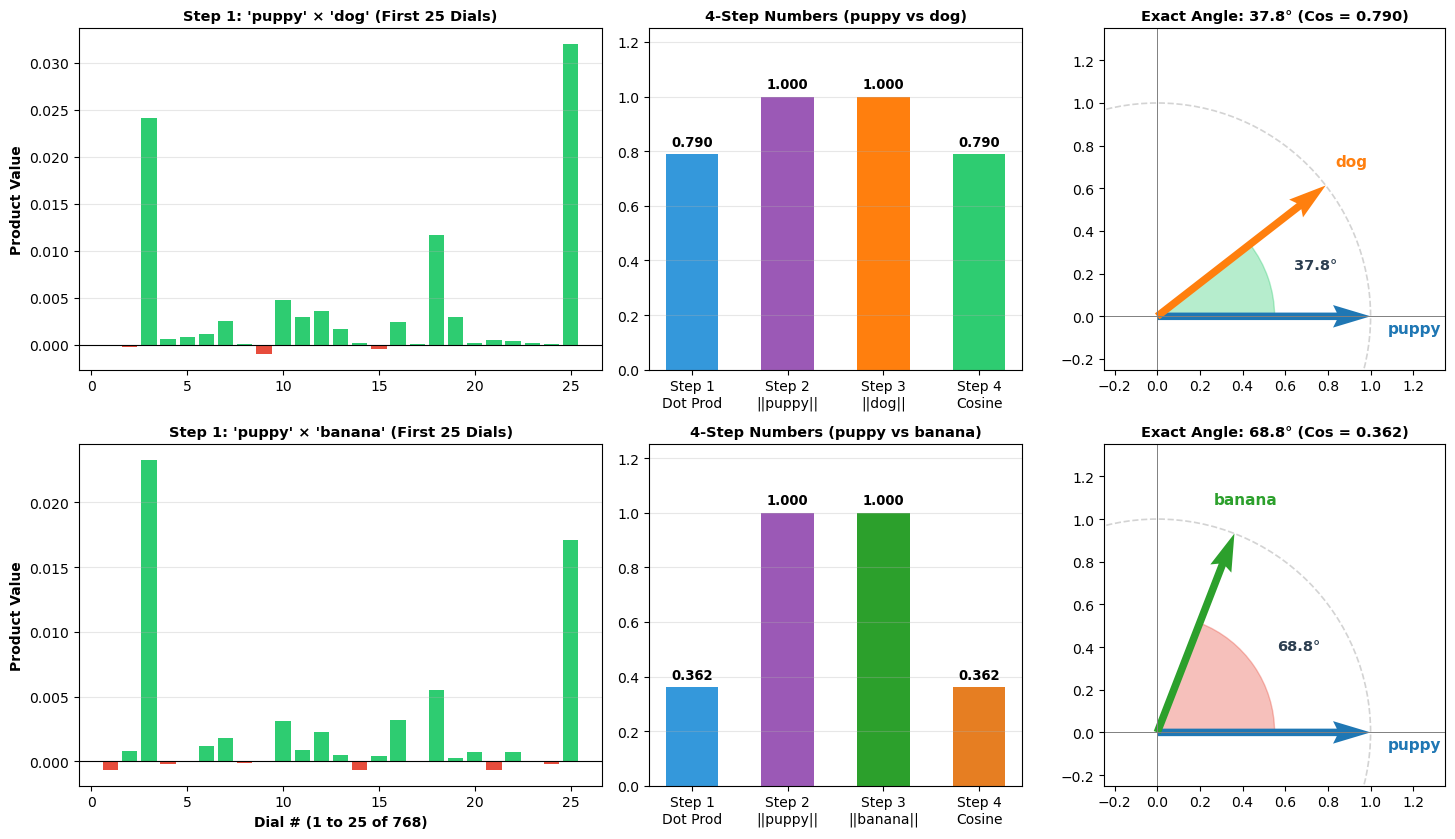

In [7]:
# %% Cell: 4-Step Cosine Cookbook + Angle Protractor Graphs
import json
import math
import urllib.request
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Wedge


def get_embeddings(texts):
    url = "http://localhost:11434/api/embed"
    payload = json.dumps({"model": "nomic-embed-text", "input": texts}).encode(
        "utf-8"
    )
    req = urllib.request.Request(
        url, data=payload, headers={"Content-Type": "application/json"}
    )
    with urllib.request.urlopen(req) as response:
        return json.loads(response.read().decode("utf-8"))["embeddings"]


def run_cookbook(name_a, vec_a, name_b, vec_b):
    # Step 1: Multiply matching dials & sum (Dot Product)
    products = [a * b for a, b in zip(vec_a, vec_b)]
    dot = sum(products)

    # Step 2 & 3: Lengths (Magnitudes) of both vectors
    len_a = math.sqrt(sum(a * a for a in vec_a))
    len_b = math.sqrt(sum(b * b for b in vec_b))

    # Step 4: Cosine Similarity & Angle in Degrees
    cos_sim = dot / (len_a * len_b)
    angle_deg = math.degrees(math.acos(max(-1.0, min(1.0, cos_sim))))

    print(f"================ {name_a.upper()} vs {name_b.upper()} ================")
    print(f"  Step 1 (Dot Product)    = {dot:.6f}")
    print(f"  Step 2 (||{name_a}||)     = {len_a:.6f}")
    print(f"  Step 3 (||{name_b}||)     = {len_b:.6f}")
    print(f"  Step 4 (Cosine Sim)     = {cos_sim:.6f}")
    print(f"  Resulting Angle (theta) = {angle_deg:.2f}°\n")

    return products, dot, len_a, len_b, cos_sim, angle_deg


# 1. Fetch vectors and run the 4-step recipe for both pairs
puppy_vec, dog_vec, banana_vec = get_embeddings(["puppy", "dog", "banana"])

dog_stats = run_cookbook("puppy", puppy_vec, "dog", dog_vec)
ban_stats = run_cookbook("puppy", puppy_vec, "banana", banana_vec)

# 2. Build a 2-Row x 3-Column Visual Dashboard
fig, axes = plt.subplots(
    2, 3, figsize=(15, 8.5), gridspec_kw={"width_ratios": [1.4, 1, 1.1]}
)

rows_data = [
    ("puppy", "dog", "#ff7f0e", dog_stats),
    ("puppy", "banana", "#2ca02c", ban_stats),
]

for row_idx, (w1, w2, target_color, stats) in enumerate(rows_data):
    products, dot, len_a, len_b, cos_sim, angle_deg = stats
    ax_bars, ax_steps, ax_angle = axes[row_idx]

    # --- COLUMN 1: Step 1 Dial Multiplications ---
    bar_colors = ["#2ecc71" if p >= 0 else "#e74c3c" for p in products[:25]]
    ax_bars.bar(range(1, 26), products[:25], color=bar_colors)
    ax_bars.axhline(0, color="black", linewidth=0.8)
    ax_bars.set_title(
        f"Step 1: '{w1}' × '{w2}' (First 25 Dials)", fontweight="bold", fontsize=10.5
    )
    ax_bars.set_ylabel("Product Value", fontweight="bold")
    if row_idx == 1:
        ax_bars.set_xlabel("Dial # (1 to 25 of 768)", fontweight="bold")
    ax_bars.grid(axis="y", alpha=0.3)

    # --- COLUMN 2: 4-Step Cookbook Summary ---
    step_labels = ["Step 1\nDot Prod", f"Step 2\n||{w1}||", f"Step 3\n||{w2}||", "Step 4\nCosine"]
    step_vals = [dot, len_a, len_b, cos_sim]
    step_cols = ["#3498db", "#9b59b6", target_color, "#2ecc71" if cos_sim > 0.7 else "#e67e22"]

    bars = ax_steps.bar(step_labels, step_vals, color=step_cols, width=0.55)
    ax_steps.set_ylim(0, 1.25)
    for b, val in zip(bars, step_vals):
        ax_steps.text(
            b.get_x() + b.get_width() / 2,
            val + 0.03,
            f"{val:.3f}",
            ha="center",
            fontweight="bold",
            fontsize=9.5,
        )
    ax_steps.set_title(f"4-Step Numbers ({w1} vs {w2})", fontweight="bold", fontsize=10.5)
    ax_steps.grid(axis="y", alpha=0.3)

    # --- COLUMN 3: Exact Angle Protractor Graph ---
    # Draw 'puppy' flat along 0° and rotate the second arrow by the exact computed angle!
    rad = math.radians(angle_deg)
    x2, y2 = math.cos(rad), math.sin(rad)

    # Protractor outer guide circle
    circle = plt.Circle((0, 0), 1.0, color="lightgray", fill=False, linestyle="--", linewidth=1.2)
    ax_angle.add_patch(circle)

    # Shaded angle wedge between the two arrows
    wedge_color = "#2ecc71" if angle_deg < 45 else "#e74c3c"
    ax_angle.add_patch(Wedge((0, 0), 0.55, 0, angle_deg, color=wedge_color, alpha=0.35))

    # Arrow 1: 'puppy' at 0°
    ax_angle.quiver(0, 0, 1, 0, angles="xy", scale_units="xy", scale=1, color="#1f77b4", width=0.022)
    ax_angle.text(1.08, -0.08, w1, color="#1f77b4", fontweight="bold", fontsize=11)

    # Arrow 2: 'dog' or 'banana' at exact angle_deg
    ax_angle.quiver(0, 0, x2, y2, angles="xy", scale_units="xy", scale=1, color=target_color, width=0.022)
    ax_angle.text(x2 * 1.15, y2 * 1.15, w2, color=target_color, fontweight="bold", fontsize=11, ha="center")

    # Angle label inside the wedge
    mid_rad = math.radians(angle_deg / 2)
    ax_angle.text(
        0.68 * math.cos(mid_rad),
        0.68 * math.sin(mid_rad),
        f"{angle_deg:.1f}°",
        fontweight="bold",
        fontsize=10.5,
        color="#2c3e50",
    )

    ax_angle.set_xlim(-0.25, 1.35)
    ax_angle.set_ylim(-0.25, 1.35)
    ax_angle.axhline(0, color="gray", linewidth=0.7)
    ax_angle.axvline(0, color="gray", linewidth=0.7)
    ax_angle.set_aspect("equal")
    ax_angle.set_title(
        f"Exact Angle: {angle_deg:.1f}° (Cos = {cos_sim:.3f})",
        fontweight="bold",
        fontsize=10.5,
    )

plt.tight_layout()
plt.show()


Grid of 3 words shape  : (3, 768) (3 rows x 768 dials)
Merged sentence shape  : (768,) (1 single arrow!)
Simple Average vs Real Context-Aware Sentence Similarity: 0.8404


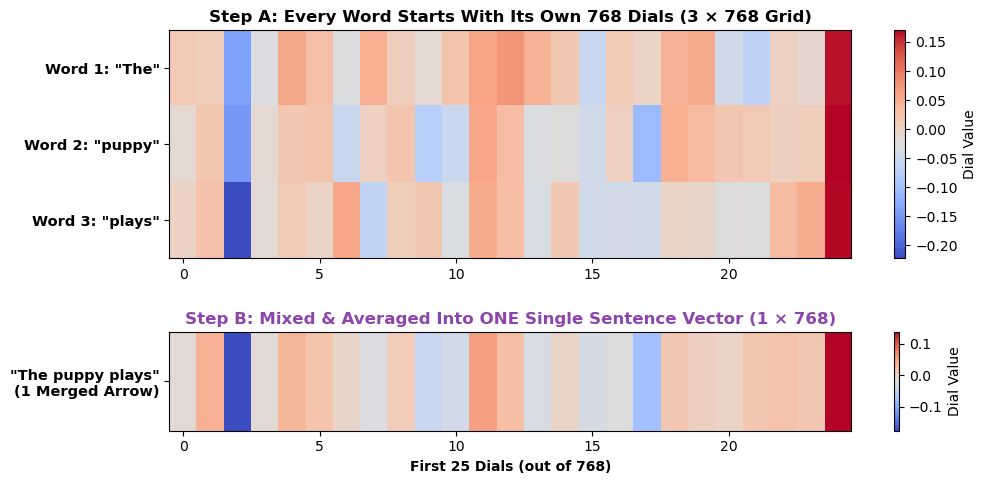

In [8]:
# %% Cell: How 3 Word Vectors Merge Into 1 Sentence Vector ("Mean Pooling")
import json
import urllib.request
import matplotlib.pyplot as plt
import numpy as np


def get_embeddings(texts):
    url = "http://localhost:11434/api/embed"
    payload = json.dumps({"model": "nomic-embed-text", "input": texts}).encode("utf-8")
    req = urllib.request.Request(url, data=payload, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req) as response:
        return np.array(json.loads(response.read().decode("utf-8"))["embeddings"])


# 1. Get vectors for each individual word AND the full sentence
items = ["The", "puppy", "plays", "The puppy plays"]
vecs = get_embeddings(items)
v_the, v_puppy, v_plays, v_real_sentence = vecs

# 2. Simulate "Mean Pooling" (averaging the 3 word rows column-by-column)
word_grid = np.vstack([v_the, v_puppy, v_plays])  # Shape: (3, 768)
v_averaged = np.mean(word_grid, axis=0)          # Shape: (768,)

# Compare the simple average against the AI's context-aware sentence vector
cos_sim = np.dot(v_averaged, v_real_sentence) / (
    np.linalg.norm(v_averaged) * np.linalg.norm(v_real_sentence)
)
print(f"Grid of 3 words shape  : {word_grid.shape} (3 rows x 768 dials)")
print(f"Merged sentence shape  : {v_real_sentence.shape} (1 single arrow!)")
print(f"Simple Average vs Real Context-Aware Sentence Similarity: {cos_sim:.4f}")

# 3. Pictorial View: 3 Word Rows -> Squashed Into 1 Sentence Row
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(11, 5.2), gridspec_kw={"height_ratios": [3, 1.3], "hspace": 0.45}
)

# Top: The 3 separate word rows
im1 = ax1.imshow(word_grid[:, :25], cmap="coolwarm", aspect="auto")
ax1.set_yticks([0, 1, 2])
ax1.set_yticklabels(['Word 1: "The"', 'Word 2: "puppy"', 'Word 3: "plays"'], fontweight="bold", fontsize=10.5)
ax1.set_title("Step A: Every Word Starts With Its Own 768 Dials (3 × 768 Grid)", fontweight="bold")
plt.colorbar(im1, ax=ax1, label="Dial Value")

# Bottom: The single merged sentence vector
im2 = ax2.imshow(v_real_sentence[:25].reshape(1, -1), cmap="coolwarm", aspect="auto")
ax2.set_yticks([0])
ax2.set_yticklabels(['"The puppy plays"\n(1 Merged Arrow)'], fontweight="bold", fontsize=10.5)
ax2.set_xlabel("First 25 Dials (out of 768)", fontweight="bold")
ax2.set_title("Step B: Mixed & Averaged Into ONE Single Sentence Vector (1 × 768)", fontweight="bold", color="#8e44ad")
plt.colorbar(im2, ax=ax2, label="Dial Value")

plt.show()


---
---
# 4-Step Cookbook + Angle Graph for "The puppy is playing" vs "the dog is barking"

=== 4-STEP SENTENCE COOKBOOK ===
Sentence A: 'The puppy is playing'
Sentence B: 'the dog is barking'

  Step 1 (Dot Product)   = 0.721959
  Step 2 (||Sentence A||)= 1.000000
  Step 3 (||Sentence B||)= 1.000000
  Step 4 (Cosine Sim)    = 0.721959
  Exact Angle (theta)    = 43.78°



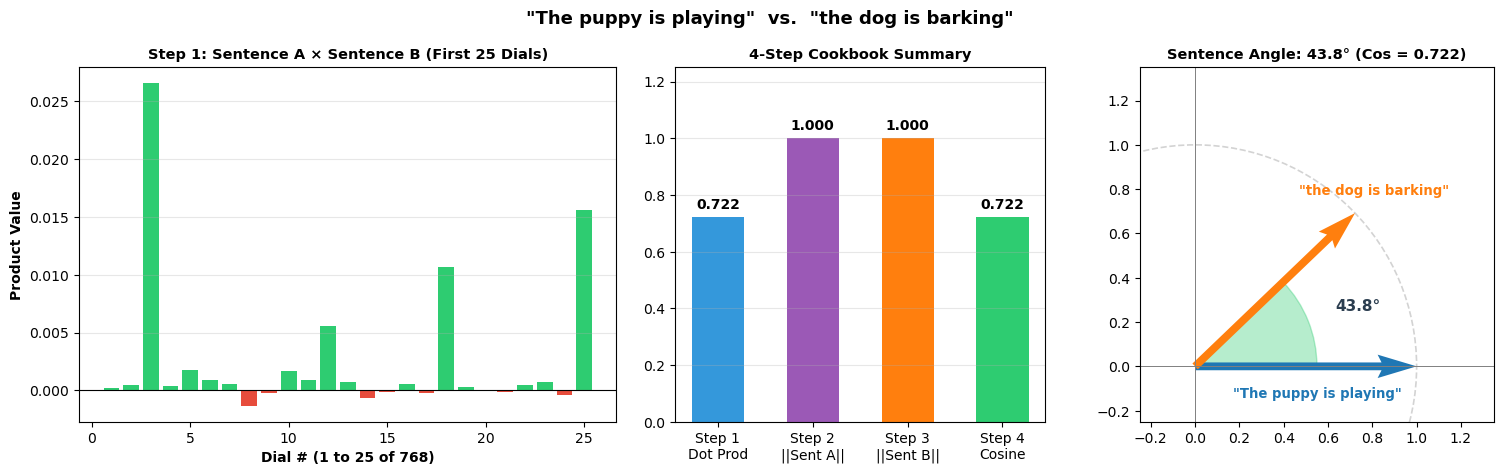

In [9]:
# %% Cell: 4-Step Cosine Cookbook + Angle Graph for Full Sentences
import json
import math
import urllib.request
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Wedge


def get_embeddings(texts):
    url = "http://localhost:11434/api/embed"
    payload = json.dumps({"model": "nomic-embed-text", "input": texts}).encode(
        "utf-8"
    )
    req = urllib.request.Request(
        url, data=payload, headers={"Content-Type": "application/json"}
    )
    with urllib.request.urlopen(req) as response:
        return json.loads(response.read().decode("utf-8"))["embeddings"]


# 1. Fetch the 768-number summary vectors for both full sentences
sent_1 = "The puppy is playing"
sent_2 = "the dog is barking"
vec_1, vec_2 = get_embeddings([sent_1, sent_2])

# 2. Run the 4-Step Cosine Similarity Cookbook
products = [a * b for a, b in zip(vec_1, vec_2)]
dot_product = sum(products)

len_1 = math.sqrt(sum(a * a for a in vec_1))
len_2 = math.sqrt(sum(b * b for b in vec_2))

cos_sim = dot_product / (len_1 * len_2)
angle_deg = math.degrees(math.acos(max(-1.0, min(1.0, cos_sim))))

# Print the 4 Cookbook Steps clearly in the console
print(f"=== 4-STEP SENTENCE COOKBOOK ===")
print(f"Sentence A: '{sent_1}'")
print(f"Sentence B: '{sent_2}'\n")
print(f"  Step 1 (Dot Product)   = {dot_product:.6f}")
print(f"  Step 2 (||Sentence A||)= {len_1:.6f}")
print(f"  Step 3 (||Sentence B||)= {len_2:.6f}")
print(f"  Step 4 (Cosine Sim)    = {cos_sim:.6f}")
print(f"  Exact Angle (theta)    = {angle_deg:.2f}°\n")

# 3. Build the 3-Panel Visual Dashboard
fig, (ax_bars, ax_steps, ax_angle) = plt.subplots(
    1, 3, figsize=(15.5, 4.8), gridspec_kw={"width_ratios": [1.45, 1, 1.15]}
)

# --- PANEL 1: Step 1 Dial-by-Dial Multiplications ---
bar_colors = ["#2ecc71" if p >= 0 else "#e74c3c" for p in products[:25]]
ax_bars.bar(range(1, 26), products[:25], color=bar_colors)
ax_bars.axhline(0, color="black", linewidth=0.8)
ax_bars.set_title("Step 1: Sentence A × Sentence B (First 25 Dials)", fontweight="bold", fontsize=10.5)
ax_bars.set_xlabel("Dial # (1 to 25 of 768)", fontweight="bold")
ax_bars.set_ylabel("Product Value", fontweight="bold")
ax_bars.grid(axis="y", alpha=0.3)

# --- PANEL 2: The 4 Cookbook Numbers ---
step_labels = ["Step 1\nDot Prod", "Step 2\n||Sent A||", "Step 3\n||Sent B||", "Step 4\nCosine"]
step_vals = [dot_product, len_1, len_2, cos_sim]
step_cols = ["#3498db", "#9b59b6", "#ff7f0e", "#2ecc71" if cos_sim > 0.7 else "#e67e22"]

bars = ax_steps.bar(step_labels, step_vals, color=step_cols, width=0.55)
ax_steps.set_ylim(0, 1.25)
for b, val in zip(bars, step_vals):
    ax_steps.text(
        b.get_x() + b.get_width() / 2,
        val + 0.03,
        f"{val:.3f}",
        ha="center",
        fontweight="bold",
        fontsize=10,
    )
ax_steps.set_title("4-Step Cookbook Summary", fontweight="bold", fontsize=10.5)
ax_steps.grid(axis="y", alpha=0.3)

# --- PANEL 3: Exact Angle Protractor Graph ---
rad = math.radians(angle_deg)
x2, y2 = math.cos(rad), math.sin(rad)

circle = plt.Circle((0, 0), 1.0, color="lightgray", fill=False, linestyle="--", linewidth=1.2)
ax_angle.add_patch(circle)

wedge_color = "#2ecc71" if angle_deg < 45 else "#f39c12"
ax_angle.add_patch(Wedge((0, 0), 0.55, 0, angle_deg, color=wedge_color, alpha=0.35))

# Arrow A: "The puppy is playing" at 0°
ax_angle.quiver(0, 0, 1, 0, angles="xy", scale_units="xy", scale=1, color="#1f77b4", width=0.022)
ax_angle.text(0.55, -0.14, '"The puppy is playing"', color="#1f77b4", fontweight="bold", fontsize=9.5, ha="center")

# Arrow B: "the dog is barking" at exact angle_deg
ax_angle.quiver(0, 0, x2, y2, angles="xy", scale_units="xy", scale=1, color="#ff7f0e", width=0.022)
ax_angle.text(x2 * 1.12, y2 * 1.12, '"the dog is barking"', color="#ff7f0e", fontweight="bold", fontsize=9.5, ha="center")

# Angle label inside the wedge
mid_rad = math.radians(angle_deg / 2)
ax_angle.text(
    0.68 * math.cos(mid_rad),
    0.68 * math.sin(mid_rad),
    f"{angle_deg:.1f}°",
    fontweight="bold",
    fontsize=11,
    color="#2c3e50",
)

ax_angle.set_xlim(-0.25, 1.35)
ax_angle.set_ylim(-0.25, 1.35)
ax_angle.axhline(0, color="gray", linewidth=0.7)
ax_angle.axvline(0, color="gray", linewidth=0.7)
ax_angle.set_aspect("equal")
ax_angle.set_title(f"Sentence Angle: {angle_deg:.1f}° (Cos = {cos_sim:.3f})", fontweight="bold", fontsize=10.5)

plt.suptitle(f'"{sent_1}"  vs.  "{sent_2}"', fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()
